In [18]:
import cv2, numpy as np, random, shutil
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

# ====== PENGATURAN ======
SRC_ROOT = Path("Dataset/dauncabee_split_aug")   # berisi test_murni, train_asli, train_aug
DST_ROOT = Path("Dataset/segmentasi")            # hasil segmentasi
CHK_ROOT = Path("Dataset/perlu_cek")             # gambar yang mencurigakan (disalin apa adanya)
OUT_SIZE = 224
MIN_AREA_RATIO = 0.02    # komponen < 2% luas gambar = noise
REL_AREA_RATIO = 0.25    # komponen < 25% dari daun terbesar = noise/bayangan
MAX_LEAVES = 3           # lebih dari ini -> perlu_cek
MODE = "split"           # "split" = tiap daun 1 file | "largest" = hanya daun terbesar
EXT = {".jpg", ".jpeg", ".png", ".bmp"}
MAX_SIDE = 1000          # gambar besar dikecilkan dulu (sisi terpanjang) sebelum disegmentasi
GC_ITERS = 5             # iterasi GrabCut
GC_MAX_SIDE = 500        # ukuran kerja GrabCut (makin besar makin halus tapi lambat)
HUE_MIN, HUE_MAX = 22, 90   # rentang hue daun (OpenCV 0-180): hijau-kuning; cokelat tanah < 22
       # ukuran kerja GrabCut (makin besar makin halus tapi lambat)

In [19]:
def leaf_mask(img_bgr):
    h, w = img_bgr.shape[:2]
    blur = cv2.GaussianBlur(img_bgr, (5, 5), 0)
    hsv = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(blur, cv2.COLOR_BGR2LAB).astype(np.float32)

    # Statistik pinggir gambar (perkiraan latar)
    b = max(3, int(0.03 * min(h, w)))
    def border(a):
        return np.concatenate([a[:b].reshape(-1, a.shape[2]), a[-b:].reshape(-1, a.shape[2]),
                               a[:, :b].reshape(-1, a.shape[2]), a[:, -b:].reshape(-1, a.shape[2])])
    bg_sat = np.median(border(hsv)[:, 1])

    if bg_sat < 50:
        # Latar netral (putih/abu-abu/kertas + bayangan): daun = piksel yang berwarna (saturasi tinggi)
        s = hsv[:, :, 1]
        t, _ = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        _, mask = cv2.threshold(s, max(t, 40), 255, cv2.THRESH_BINARY)
    else:
        # Latar berwarna (mis. hijau): jarak warna ke warna latar
        bg = np.median(border(lab), axis=0)
        d = np.linalg.norm(lab - bg, axis=2)
        d8 = cv2.normalize(d, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
        _, mask = cv2.threshold(d8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k, iterations=2)

    # isi lubang di dalam daun
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(mask)
    cv2.drawContours(filled, cnts, -1, 255, thickness=cv2.FILLED)
    return filled


def normalize(crop):
    h, w = crop.shape[:2]
    s = max(h, w)
    canvas = np.zeros((s, s, 3), np.uint8)
    canvas[(s-h)//2:(s-h)//2+h, (s-w)//2:(s-w)//2+w] = crop
    return cv2.resize(canvas, (OUT_SIZE, OUT_SIZE), interpolation=cv2.INTER_AREA)


def split_leaves(img_bgr, mask):
    """return (daftar_daun, flag). flag = None kalau aman, selain itu alasan perlu dicek."""
    h, w = mask.shape
    ratio = (mask > 0).mean()
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    areas = {i: stats[i, cv2.CC_STAT_AREA] for i in range(1, n)}
    if not areas:
        return [], "tidak_ada_daun"
    biggest = max(areas.values())
    keep = [i for i, a in areas.items() if a >= MIN_AREA_RATIO*h*w and a >= REL_AREA_RATIO*biggest]
    if not keep:
        return [], "tidak_ada_daun"

    flag = None
    if ratio > 0.85:
        flag = "mask_terlalu_luas"          # biasanya foto banyak tanaman / latar tidak terpisah
    elif len(keep) > MAX_LEAVES:
        flag = "terlalu_banyak_objek"

    keep.sort(key=lambda i: -areas[i])
    if MODE == "largest":
        keep = keep[:1]
    else:
        keep.sort(key=lambda i: stats[i, cv2.CC_STAT_LEFT])   # kiri -> kanan

    leaves = []
    for i in keep:
        x, y, bw, bh = (stats[i, cv2.CC_STAT_LEFT], stats[i, cv2.CC_STAT_TOP],
                        stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT])
        m = (labels[y:y+bh, x:x+bw] == i).astype(np.uint8) * 255
        roi = img_bgr[y:y+bh, x:x+bw]
        leaves.append(normalize(cv2.bitwise_and(roi, roi, mask=m)))   # latar & daun lain -> hitam
    return leaves, flag

In [20]:
def load_img(path):
    """Baca gambar, kecilkan jika sisi terpanjang > MAX_SIDE (gambar kecil tidak dibesarkan)."""
    img = cv2.imread(str(path))
    if img is None:
        return None
    s = MAX_SIDE / max(img.shape[:2])
    if s < 1:
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img


def color_prior(img_bgr):
    """Piksel 'warna daun': hijau-kuning (hue ~22-90), cukup jenuh & tidak terlalu gelap.
    Tanah/batu (cokelat, hue < 22 atau saturasi rendah) dan cabai merah tidak termasuk."""
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    return ((h >= HUE_MIN) & (h <= HUE_MAX) & (s >= 50) & (v >= 30)).astype(np.uint8) * 255


def grabcut_mask(img_bgr, init_mask, iters=GC_ITERS, max_side=GC_MAX_SIDE):
    """Haluskan mask awal dengan GrabCut, dibantu prior warna daun agar tanah/batu tidak ikut."""
    h, w = init_mask.shape
    s = min(1.0, max_side / max(h, w))
    small = cv2.resize(img_bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    init = cv2.resize(init_mask, (small.shape[1], small.shape[0]), interpolation=cv2.INTER_NEAREST)
    prior = color_prior(cv2.GaussianBlur(small, (5, 5), 0))
    leafish = cv2.bitwise_and(init, prior)              # di dalam mask awal DAN berwarna daun

    k = max(3, int(0.03 * min(small.shape[:2])) | 1)
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    core = cv2.erode(leafish, ker)                      # pasti daun
    near = cv2.dilate(init, ker)                        # di luar ini pasti latar

    gc = np.full(init.shape, cv2.GC_PR_BGD, np.uint8)   # default: kemungkinan latar (termasuk tanah di dalam mask)
    gc[leafish > 0] = cv2.GC_PR_FGD
    gc[core > 0] = cv2.GC_FGD
    gc[near == 0] = cv2.GC_BGD
    if not (gc == cv2.GC_FGD).any() or not (gc == cv2.GC_BGD).any():
        return init_mask
    try:
        bgd = np.zeros((1, 65), np.float64); fgd = np.zeros((1, 65), np.float64)
        cv2.grabCut(small, gc, None, bgd, fgd, iters, cv2.GC_INIT_WITH_MASK)
    except cv2.error:
        return init_mask

    m = np.where((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
    m = cv2.resize(m, (w, h), interpolation=cv2.INTER_NEAREST)
    k2 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k2)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k2, iterations=2)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(m)
    cv2.drawContours(filled, cnts, -1, 255, thickness=cv2.FILLED)
    return filled


def segment(img):
    """return (daun, flag, mask_awal, mask_grabcut).
    Jika flag (perlu cek) pada mask awal, GrabCut TIDAK dijalankan."""
    m0 = leaf_mask(img)
    _, flag = split_leaves(img, m0)
    if flag:
        return [], flag, m0, None
    m1 = grabcut_mask(img, m0)
    leaves, flag = split_leaves(img, m1)
    return leaves, flag, m0, m1

Total gambar: 1348


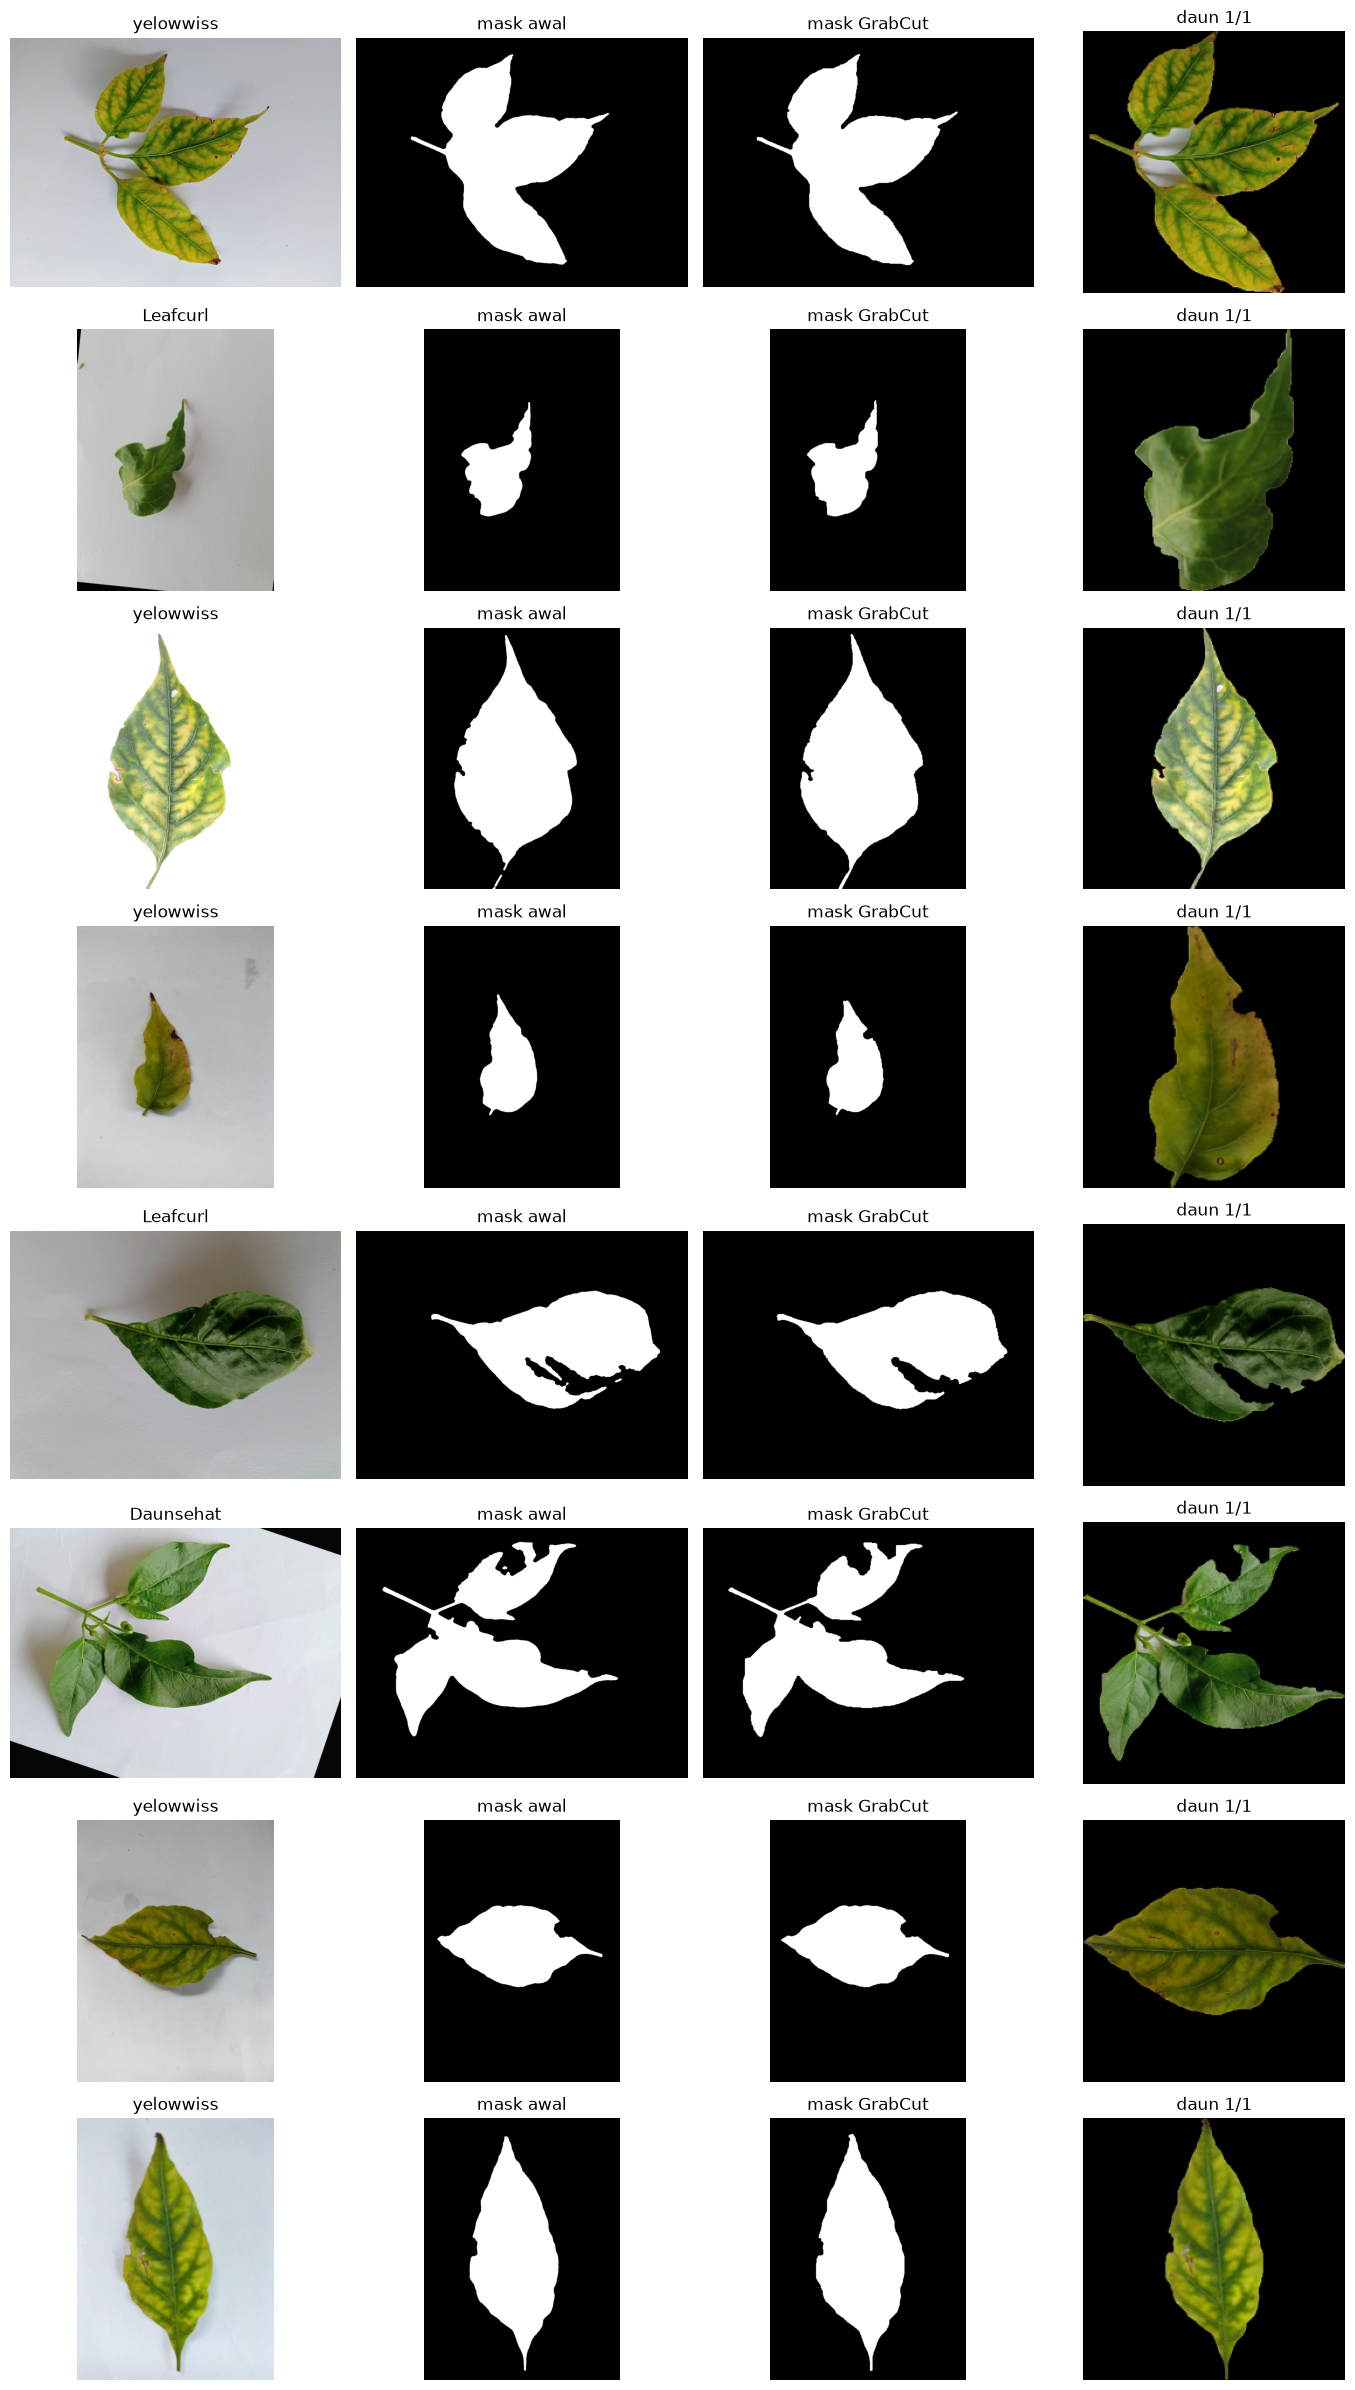

In [21]:
files = [p for p in SRC_ROOT.rglob("*") if p.suffix.lower() in EXT]
print("Total gambar:", len(files))

def preview(sample):
    fig, ax = plt.subplots(len(sample), 4, figsize=(14, 3*len(sample)))
    for r, p in enumerate(sample):
        img = load_img(p)
        leaves, flag, m0, m1 = segment(img)
        ax[r, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[r, 0].set_title(p.parent.name)
        ax[r, 1].imshow(m0, cmap="gray"); ax[r, 1].set_title("mask awal")
        if flag:
            ax[r, 2].text(0.5, 0.5, "PERLU CEK\n" + flag, ha="center", va="center")
        else:
            ax[r, 2].imshow(m1, cmap="gray"); ax[r, 2].set_title("mask GrabCut")
            if leaves:
                ax[r, 3].imshow(cv2.cvtColor(leaves[0], cv2.COLOR_BGR2RGB))
                ax[r, 3].set_title(f"daun 1/{len(leaves)}")
        for a in ax[r]: a.axis("off")
    plt.tight_layout(); plt.show()

preview(random.sample(files, 8))

In [22]:
for sp in ["train_asli", "train_aug", "test_murni"]:
    d = SRC_ROOT / sp
    n = len([p for p in d.rglob("*") if p.suffix.lower() in EXT]) if d.exists() else None
    print(f"{sp:12s} ->", "FOLDER TIDAK ADA di " + str(d) if n is None else f"{n} gambar")

train_asli   -> 423 gambar
train_aug    -> 819 gambar
test_murni   -> 106 gambar


In [23]:
import pandas as pd
from collections import defaultdict

# bersihkan hasil lama supaya tidak tercampur
for r in (DST_ROOT, CHK_ROOT):
    if r.exists():
        shutil.rmtree(r)

files = [p for p in SRC_ROOT.rglob("*") if p.suffix.lower() in EXT]
rekap = defaultdict(Counter)
for p in files:
    rel = p.relative_to(SRC_ROOT)
    split = rel.parts[0]
    img = load_img(p)
    rekap[split]["gambar_sumber"] += 1
    if img is None:
        rekap[split]["gagal_baca"] += 1
        continue
    leaves, flag, _, _ = segment(img)
    if flag:                                            # perlu cek: disalin apa adanya, TIDAK disegmentasi
        rekap[split]["perlu_cek"] += 1
        (CHK_ROOT / rel.parent).mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, CHK_ROOT / rel)
        continue
    rekap[split]["file_hasil"] += len(leaves)
    out_dir = DST_ROOT / rel.parent
    out_dir.mkdir(parents=True, exist_ok=True)
    for j, lf in enumerate(leaves):
        cv2.imwrite(str(out_dir / f"{p.stem}_d{j+1}.png"), lf)

pd.DataFrame(rekap).T.fillna(0).astype(int)

,gambar_sumber,file_hasil,perlu_cek
test_murni,106,109,0
train_asli,423,435,6
train_aug,819,835,11
